# Wstępna analiza danych tekstowych (EDA)
Cel: poznanie zbioru ai-detection-demo przed czyszczeniem – rozkład typów tekstów, modeli i źródeł, braki, duplikaty, długość tekstów i ewentualne artefakty.

## 1. Biblioteki

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import datasets
from datasets import load_dataset

print("Python:", sys.version.split()[0])
for lib in (np, pd, matplotlib, datasets):
    print(f"{lib.__name__}: {lib.__version__}")

Python: 3.12.8
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.11.2
datasets: 5.1.0


## 2. Wczytywanie danych

In [2]:
dataset = load_dataset("DarrenJiaImbue/ai-detection-demo-dataset")
dataset

DatasetDict({
    train: Dataset({
        features: ['text_id', 'text', 'cosine_score', 'text_type', 'model', 'source', 'source_id', 'source_text', 'split', 'label', 'edit_prompt', 'provider', 'extracted_metadata', 'source_word_count'],
        num_rows: 75316
    })
    val: Dataset({
        features: ['text_id', 'text', 'cosine_score', 'text_type', 'model', 'source', 'source_id', 'source_text', 'split', 'label', 'edit_prompt', 'provider', 'extracted_metadata', 'source_word_count'],
        num_rows: 3234
    })
    test: Dataset({
        features: ['text_id', 'text', 'cosine_score', 'text_type', 'model', 'source', 'source_id', 'source_text', 'split', 'label', 'edit_prompt', 'provider', 'extracted_metadata', 'source_word_count'],
        num_rows: 7658
    })
})

In [3]:
df = pd.concat([
    dataset["train"].to_pandas(),
    dataset["val"].to_pandas(),
    dataset["test"].to_pandas(),
], ignore_index=True)

df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 86208 entries, 0 to 86207
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   text_id             86208 non-null  str    
 1   text                86208 non-null  str    
 2   cosine_score        86208 non-null  float64
 3   text_type           86208 non-null  str    
 4   model               86208 non-null  str    
 5   source              86208 non-null  str    
 6   source_id           86208 non-null  str    
 7   source_text         86208 non-null  str    
 8   split               86208 non-null  str    
 9   label               86208 non-null  int64  
 10  edit_prompt         28689 non-null  str    
 11  provider            86208 non-null  str    
 12  extracted_metadata  28750 non-null  str    
 13  source_word_count   86208 non-null  int64  
dtypes: float64(1), int64(2), str(11)
memory usage: 259.2 MB


In [4]:
df[["text", "text_type", "model", "source", "split"]].head(10)

,text,text_type,model,source,split
0,The sound card was not compatible with Flight ...,human_written,human,amazon_reviews,train
1,"Very nicely written and presented, the heartwa...",human_written,human,amazon_reviews,train
2,Don''t buy it. My dog loves the treat. HOWEVER...,human_written,human,amazon_reviews,train
3,This book does a great job of citing the peopl...,human_written,human,amazon_reviews,train
4,It reminded me of a novel in that it has no ta...,human_written,human,amazon_reviews,train
5,"This went into theory of movement, and how to ...",human_written,human,amazon_reviews,train
6,"In this case, the Kindle itself seems to be th...",human_written,human,amazon_reviews,train
7,"When I viewed this DVD, I was in tears due to ...",human_written,human,amazon_reviews,train
8,This book is a wonderful depiction of the hist...,human_written,human,amazon_reviews,train
9,"The name of the CD, Blues Juice, really fools ...",human_written,human,amazon_reviews,train


### Obserwacje

- Zbiór ma 86 208 tekstów: train 75 316, val 3 234, test 7 658 (ok. 87% / 4% / 9%).
- Kolumna `text` nie ma brakujących wartości.
- `edit_prompt` jest wypełnione tylko w 28 689 wierszach, a `extracted_metadata` tylko w 28 750 – to dokładnie liczba tekstów `ai_edited` i `ai_generated`, czyli zgodnie z opisem zbioru te kolumny dotyczą tylko tekstów AI.
- Kolumny `cosine_score`, `model`, `provider`, `text_type`, `label`, `edit_prompt`, `extracted_metadata` i `source_text` zdradzają typ tekstu, więc nie mogą być cechami modelu.

## 3. Rozkład typów tekstów, modeli i źródeł

In [5]:
pd.crosstab(df["text_type"], df["model"], margins=True)

model,claude-sonnet-4-6,gemini-3-flash-preview,gpt-5.3-chat-latest,human,All
text_type,,,,,
ai_edited,9545,9573,9571,0,28689
ai_generated,9556,9574,9620,0,28750
human_written,0,0,0,28769,28769
All,19101,19147,19191,28769,86208


In [6]:
pd.crosstab(df["source"], df["text_type"], margins=True)

text_type,ai_edited,ai_generated,human_written,All
source,,,,
amazon_reviews,5000,5000,5000,15000
fineweb_edu,4993,4988,5000,14981
news,4934,4999,5000,14933
reddit_writing_prompts,4993,4995,5000,14988
twitter,3769,3769,3769,11307
yelp_reviews,5000,4999,5000,14999
All,28689,28750,28769,86208


In [7]:
pd.crosstab(df["split"], df["text_type"], margins=True)

text_type,ai_edited,ai_generated,human_written,All
split,,,,
test,2553,2552,2553,7658
train,25057,25122,25137,75316
val,1079,1076,1079,3234
All,28689,28750,28769,86208


### Obserwacje

- Trzy typy tekstów są prawie równoliczne: 28 769 `human_written`, 28 750 `ai_generated` i 28 689 `ai_edited`.
- Teksty AI są podzielone prawie po równo między trzy modele (ok. 9 500 na model w każdym typie).
- Pięć źródeł ma po 5 000 tekstów ludzkich, a Twitter 3 769. W niektórych źródłach jest kilka-kilkadziesiąt tekstów AI mniej niż ludzkich (np. news: 4 934 `ai_edited`), więc części tekstów ludzkich brakuje odpowiednika AI.
- Proporcje typów są takie same w każdym splicie. Split val jest mały (ok. 4% zbioru).

## 4. Braki i puste teksty

In [8]:
empty = df["text"].str.strip() == ""
print("Puste teksty:", empty.sum())

Puste teksty: 0


### Obserwacje

- Nie ma pustych tekstów ani brakujących wartości.

## 5. Duplikaty

In [9]:
duplicates = df.duplicated(subset="text", keep="first")
print("Nadmiarowe kopie:", duplicates.sum())
print(df[duplicates]["text_type"].value_counts())

Nadmiarowe kopie: 14
text_type
ai_edited    14
Name: count, dtype: int64


In [10]:
all_copies = df[df.duplicated(subset="text", keep=False)]

types_per_text = all_copies.groupby("text")["text_type"].nunique()
print("Teksty z więcej niż jednym typem:", (types_per_text > 1).sum())

splits_per_text = all_copies.groupby("text")["split"].nunique()
print("Teksty występujące w więcej niż jednym splicie:", (splits_per_text > 1).sum())

Teksty z więcej niż jednym typem: 14
Teksty występujące w więcej niż jednym splicie: 0


In [11]:
all_copies.sort_values("text")[["text", "text_type", "model", "split"]].head(20)

,text,text_type,model,split
25058,#MusicMatters -142 #EGHRadio is available for ...,human_written,human,train
44100,#MusicMatters -142 #EGHRadio is available for ...,ai_edited,claude-sonnet-4-6,train
76321,#Refugee women in #CampMoria often ask us for ...,human_written,human,val
77345,#Refugee women in #CampMoria often ask us for ...,ai_edited,gemini-3-flash-preview,val
17680,A huge leap at the last put Enda Bolger's stab...,human_written,human,train
62904,A huge leap at the last put Enda Bolger's stab...,ai_edited,gemini-3-flash-preview,train
2501,"Bernard Goldberg names names, some obvious (li...",human_written,human,train
67557,"Bernard Goldberg names names, some obvious (li...",ai_edited,claude-sonnet-4-6,train
22937,Birds of Prey (and the Fantabulous Emancipatio...,human_written,human,train
72994,Birds of Prey (and the Fantabulous Emancipatio...,ai_edited,claude-sonnet-4-6,train


### Obserwacje

- Jest 14 powtórzonych tekstów i wszystkie to `ai_edited`, identyczne ze swoim ludzkim oryginałem. Są to edycje, w których model nie zmienił niczego w tekście.
- Takie teksty mają etykietę AI, ale w rzeczywistości są tekstem człowieka, więc przy czyszczeniu zostaną usunięte.
- Żaden powtórzony tekst nie występuje w więcej niż jednym splicie.

## 6. Powiązanie tekstów przez source_id

In [12]:
types_per_source = df.groupby("source_id")["text_type"].nunique()
types_per_source.value_counts()

text_type
3    28670
2       99
Name: count, dtype: int64

In [13]:
splits_per_source = df.groupby("source_id")["split"].nunique()
print("Teksty źródłowe w więcej niż jednym splicie:", (splits_per_source > 1).sum())

Teksty źródłowe w więcej niż jednym splicie: 0


### Obserwacje

- 28 670 tekstów źródłowych ma komplet trzech wersji (human, ai_generated, ai_edited), a 99 ma tylko dwie – brakuje im jednej wersji AI.
- Każdy tekst źródłowy i wszystkie jego wersje są w tym samym splicie. Oficjalny podział nie ma więc wycieku tematu między train i test i można go używać.

## 7. Długość tekstów

In [14]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.count(r"\S+")

df.groupby("text_type")["n_words"].describe()

,count,mean,std,min,25%,50%,75%,max
text_type,,,,,,,,
ai_edited,28689.0,240.906759,211.458201,7.0,76.0,177.0,345.0,1599.0
ai_generated,28750.0,245.125704,222.305478,1.0,56.0,165.0,380.0,1330.0
human_written,28769.0,244.443324,215.568343,20.0,56.0,167.0,391.0,800.0


In [15]:
df["length_ratio"] = df["n_words"] / df["source_word_count"]
df.groupby("text_type")["length_ratio"].describe()

,count,mean,std,min,25%,50%,75%,max
text_type,,,,,,,,
ai_edited,28689.0,1.176437,0.653607,0.119869,0.875000,1.018868,1.288660,13.142857
ai_generated,28750.0,0.996346,0.063389,0.002415,0.969697,1.000000,1.018182,2.069565
human_written,28769.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [16]:
df.pivot_table(index="source", columns="text_type", values="n_words", aggfunc="median")

text_type,ai_edited,ai_generated,human_written
source,,,
amazon_reviews,79.0,63.0,65.0
fineweb_edu,320.0,351.0,367.5
news,301.0,359.0,375.0
reddit_writing_prompts,365.0,375.0,373.0
twitter,41.0,33.0,33.0
yelp_reviews,119.0,101.0,102.0


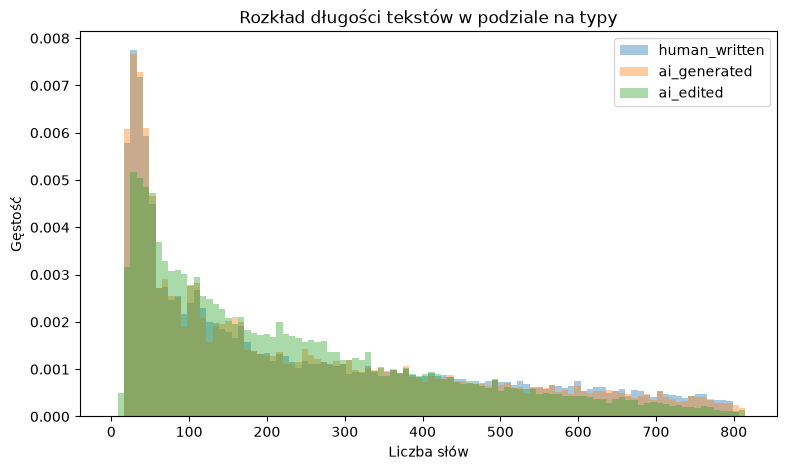

In [17]:
limit = df["n_words"].quantile(0.99)

plt.figure(figsize=(9, 5))
for t in ["human_written", "ai_generated", "ai_edited"]:
    plt.hist(df[df["text_type"] == t]["n_words"], bins=100, range=(0, limit),
             alpha=0.4, density=True, label=t)
plt.xlabel("Liczba słów")
plt.ylabel("Gęstość")
plt.title("Rozkład długości tekstów w podziale na typy")
plt.legend()
plt.savefig("../figures/text_01_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
short_ai = df[(df["text_type"] != "human_written") & (df["n_words"] < 20)]
print("Teksty AI krótsze niż 20 słów:", len(short_ai))
print(short_ai["text_type"].value_counts())
short_ai[["text", "text_type", "source", "source_word_count"]].head(10)

Teksty AI krótsze niż 20 słów: 344
text_type
ai_edited       272
ai_generated     72
Name: count, dtype: int64


,text,text_type,source,source_word_count
25165,"As of 4:43 p.m. on December 13, 2020, Adam Gas...",ai_edited,twitter,23
25299,2021 All Ireland Senior Championship: 1:12(15)...,ai_edited,twitter,21
25335,It closed before I could sign my name. Now I h...,ai_edited,amazon_reviews,21
25467,"DTLA looks so good right now. Seriously, let’s...",ai_edited,twitter,22
25507,Overdose: The New Video. {{USERNAME}} G.Baki f...,ai_edited,twitter,20
25545,"""Oasis - Sunday Morning Call Live [DVD Quality]""",ai_edited,twitter,35
25685,The story was authentic but the acting dull an...,ai_edited,amazon_reviews,24
25984,"""Congratulations to:\n\n- Comeback Player of t...",ai_edited,twitter,20
26125,Ranking BGYO music videos is impossible becaus...,ai_generated,twitter,20
26200,"""Live sports tonight!! Still weird without fan...",ai_edited,twitter,23


### Obserwacje

- Teksty ludzkie i `ai_generated` mają prawie identyczny rozkład długości (mediana 167 i 165 słów), także w każdym źródle osobno. Długość nie zdradza więc typu tekstu – inaczej niż w poprzednio rozważanym zbiorze.
- Dla `ai_generated` stosunek długości do oryginału ma medianę 1,00, a połowa tekstów mieści się w przedziale 0,97–1,02, więc modele trzymały się zadanej długości.
- Teksty `ai_edited` są średnio dłuższe od oryginału (średnio 1,18 raza, maksymalnie ponad 13 razy), co wynika z poleceń edycji, np. rozwinięcia tekstu.
- Teksty ludzkie mają od 20 do 800 słów, a część tekstów AI jest krótsza niż 20 słów (minimum 1 słowo).
- 344 teksty AI są krótsze niż 20 słów (272 `ai_edited`, 72 `ai_generated`). Pochodzą głównie z krótkich tweetów i recenzji. Przy tak krótkich tekstach cechy stylometryczne są mało wiarygodne.

## 8. Artefakty w tekstach

In [19]:
text = df["text"]

checks = pd.DataFrame()
checks["starts_lowercase"] = text.str.match(r"[a-z]")
checks["ends_with_punctuation"] = text.str.contains(r"[.!?]$")
checks["missing_space_after_dot"] = text.str.contains(r"[a-z][.!?][A-Z]")
checks["has_quote"] = text.str.contains(r'["“”]')
checks["has_dash"] = text.str.contains(r"[—–]")
checks["has_non_ascii"] = text.str.contains(r"[^\x00-\x7F]")
checks["has_double_space"] = text.str.contains("  ", regex=False)
checks["has_newline"] = text.str.contains("\n", regex=False)
checks["has_markdown_bold"] = text.str.contains("**", regex=False)
checks["has_canvas_fence"] = text.str.contains(":::", regex=False)
checks["has_curly_quote"] = text.str.contains(r"[’‘“”]")
checks["text_type"] = df["text_type"]

(checks.groupby("text_type").mean() * 100).T

text_type,ai_edited,ai_generated,human_written
starts_lowercase,0.596047,0.027826,2.120338
ends_with_punctuation,73.697236,88.643478,72.181862
missing_space_after_dot,0.355537,0.017391,5.672773
has_quote,46.878595,41.979130,25.885502
has_dash,49.032730,41.217391,7.636692
has_non_ascii,67.485796,62.045217,27.505301
has_double_space,3.280003,0.396522,10.893670
has_newline,61.068702,58.695652,43.181897
has_markdown_bold,2.439960,11.586087,1.824881
has_canvas_fence,0.010457,4.080000,0.006952


In [20]:
checks["source"] = df["source"]
(checks.groupby(["source", "text_type"])["has_newline"].mean() * 100).unstack()

text_type,ai_edited,ai_generated,human_written
source,,,
amazon_reviews,14.300000,14.920000,0.00
fineweb_edu,96.955738,97.193264,97.58
news,86.603162,95.479096,55.34
reddit_writing_prompts,97.436411,98.198198,95.54
twitter,5.943221,0.106129,0.00
yelp_reviews,52.040000,31.986397,0.00


In [21]:
beginnings = df["text"].str.slice(0, 30)

for t in ["human_written", "ai_generated", "ai_edited"]:
    print("===", t, "===")
    print(beginnings[df["text_type"] == t].value_counts().head(10))

=== human_written ===
text
Media playback is not supporte    77
Check out what I just added to    20
Media playback is unsupported     13
# # # # # # [ ] ( # dropcap )      9
from The American Heritage® Di     7
Earning #cryptocurrency for se     7
This section is from the book      6
Send the link below via email      5
I was very disappointed with t     4
I was pleasantly surprised by      4
Name: count, dtype: int64
=== ai_generated ===
text
I really wanted to love this p    218
I really wanted to like this p    182
Absolutely terrible experience     47
I rarely leave negative review     38
I wanted to like this place, b     33
I am beyond disappointed with      32
This album is an absolute mast     27
Absolutely fantastic experienc     26
I rarely leave reviews, but th     25
I don’t usually leave reviews,     23
Name: count, dtype: int64
=== ai_edited ===
text
Media playback is not supporte    51
Charlotte Douglas Internationa     6
from The American Heritage® Di     5
Happy #Inte

### Obserwacje

- Pauzę (—, –) ma 41% tekstów `ai_generated` i 49% `ai_edited`, a tylko 8% ludzkich. To prawdopodobnie prawdziwa cecha stylu współczesnych modeli.
- Teksty `ai_generated` często zaczynają się od tych samych schematów, np. „I really wanted to love/like this place” (ok. 400 razy), „Absolutely terrible experience”, „I rarely leave negative reviews”.
- Teksty ludzkie mają artefakty pobierania danych: brak spacji po kropce (5,7% wobec ok. 0% w AI), podwójne spacje (10,9% wobec 0,4% w `ai_generated`) i szablonowe początki stron (np. „Media playback is not supported”). Szablony przechodzą też do `ai_edited`.
- Teksty AI mają artefakty formatowania czatu: pogrubienia markdown `**` (11,6% `ai_generated`) i znaczniki `:::` (4,1%).
- Typograficzne apostrofy i cudzysłowy ma 41–44% tekstów AI i 19% ludzkich. Ich kształt zależy od programu, w którym powstał tekst, a nie od autora.
- W recenzjach z Amazona i Yelp oraz w tweetach teksty ludzkie nie mają ani jednego znaku nowej linii, a teksty AI mają (15–52% w recenzjach). Podział na akapity został usunięty z tych źródeł przy tworzeniu oryginalnych zbiorów.
- Przy czyszczeniu artefakty pobierania i formatowania zostaną ujednolicone w obu klasach, a cechy stylu (pauzy, schematyczne początki) zostaną zachowane.